# Sentiment Analysis

This notebook performs sentiment analysis on hotel reviews to classify them as Positive, Negative, or Neutral.

In [6]:
import pandas as pd
import numpy as np

In [7]:
df = pd.read_csv("../data/processed/Hotel_Reviews_Preprocessed.csv")
df.head()

,Hotel_Address,Additional_Number_of_Scoring,Review_Date,Average_Score,Hotel_Name,Reviewer_Nationality,Negative_Review,Review_Total_Negative_Word_Counts,Total_Number_of_Reviews,Positive_Review,Review_Total_Positive_Word_Counts,Total_Number_of_Reviews_Reviewer_Has_Given,Reviewer_Score,Tags,days_since_review,lat,lng,Review_Text,Processed_Review
0,s Gravesandestraat 55 Oost 1092 AA Amsterdam N...,194,2017-08-03,7.7,Hotel Arena,Russia,I am so angry that i made this post available ...,397,1403,Only the park outside of the hotel was beautiful,11,7,2.9,"[' Leisure trip ', ' Couple ', ' Duplex Double...",0,52.360576,4.915968,only the park outside of the hotel was beautif...,park outside hotel beautiful angry made post a...
1,s Gravesandestraat 55 Oost 1092 AA Amsterdam N...,194,2017-08-03,7.7,Hotel Arena,Ireland,No Negative,0,1403,No real complaints the hotel was great great l...,105,7,7.5,"[' Leisure trip ', ' Couple ', ' Duplex Double...",0,52.360576,4.915968,no real complaints the hotel was great great l...,no real complaint hotel great great location s...
2,s Gravesandestraat 55 Oost 1092 AA Amsterdam N...,194,2017-07-31,7.7,Hotel Arena,Australia,Rooms are nice but for elderly a bit difficult...,42,1403,Location was good and staff were ok It is cute...,21,9,7.1,"[' Leisure trip ', ' Family with young childre...",3,52.360576,4.915968,location was good and staff were ok it is cute...,location good staff ok cute hotel breakfast ra...
3,s Gravesandestraat 55 Oost 1092 AA Amsterdam N...,194,2017-07-31,7.7,Hotel Arena,United Kingdom,My room was dirty and I was afraid to walk bar...,210,1403,Great location in nice surroundings the bar an...,26,1,3.8,"[' Leisure trip ', ' Solo traveler ', ' Duplex...",3,52.360576,4.915968,great location in nice surroundings the bar an...,great location nice surroundings bar restauran...
4,s Gravesandestraat 55 Oost 1092 AA Amsterdam N...,194,2017-07-24,7.7,Hotel Arena,New Zealand,You When I booked with your company on line yo...,140,1403,Amazing location and building Romantic setting,8,3,6.7,"[' Leisure trip ', ' Couple ', ' Suite ', ' St...",10,52.360576,4.915968,amazing location and building romantic setting...,amazing location building romantic setting boo...


In [8]:
df.shape

(515212, 19)

In [9]:
df.columns.tolist()

['Hotel_Address',
 'Additional_Number_of_Scoring',
 'Review_Date',
 'Average_Score',
 'Hotel_Name',
 'Reviewer_Nationality',
 'Negative_Review',
 'Review_Total_Negative_Word_Counts',
 'Total_Number_of_Reviews',
 'Positive_Review',
 'Review_Total_Positive_Word_Counts',
 'Total_Number_of_Reviews_Reviewer_Has_Given',
 'Reviewer_Score',
 'Tags',
 'days_since_review',
 'lat',
 'lng',
 'Review_Text',
 'Processed_Review']

In [10]:
df["Processed_Review"].isna().sum()

np.int64(26)

In [11]:
(df["Processed_Review"].fillna("").str.strip() == "").sum()

np.int64(26)

In [12]:
df = df[df["Processed_Review"].fillna("").str.strip() != ""].copy()

In [13]:
df.shape

(515186, 19)

In [14]:
df["Processed_Review"].sample(10, random_state=42).tolist()

['staff ultra efficient friendly enough breakfast amazing room bit shabby need updating shower head work well impressed charged 55 4 cocktail either thought car park cost extortionate',
 'fast check lovely room conveniently situated keep coming back grange st paul choice staying central london business seeing friend seems quiet relaxed not main business tourist spot hotel offer need short stay clean comfortable room excellent breakfast 24 hour bar food within walking city short taxi ride west end no negative',
 'beach lover proximity hotel barcelona beach paramount no negative',
 'arrival room discovered twin double although took time get reception quickly sorted moved another room upgraded impressed way staff dealt mistake slow response phone call attempting sort room waited sometime queue reception',
 'everything place good except add checked good told u wifi extra use pool extra use gym extra breakfast extra 2015 almost 2016 please get stop trying fleece people',
 'vast breakfast ch

In [15]:
df["Reviewer_Score"].describe()

count    515186.000000
mean          8.395508
std           1.637463
min           2.500000
25%           7.500000
50%           8.800000
75%           9.600000
max          10.000000
Name: Reviewer_Score, dtype: float64

In [16]:
df["Rating_Sentiment"] = np.select(
    [
        df["Reviewer_Score"] >= 7,
        df["Reviewer_Score"] < 5
    ],
    [
        "Positive",
        "Negative"
    ],
    default="Neutral"
)

In [17]:
df["Rating_Sentiment"].value_counts()

Rating_Sentiment
Positive    428471
Neutral      64484
Negative     22231
Name: count, dtype: int64

<Axes: xlabel='Rating_Sentiment'>

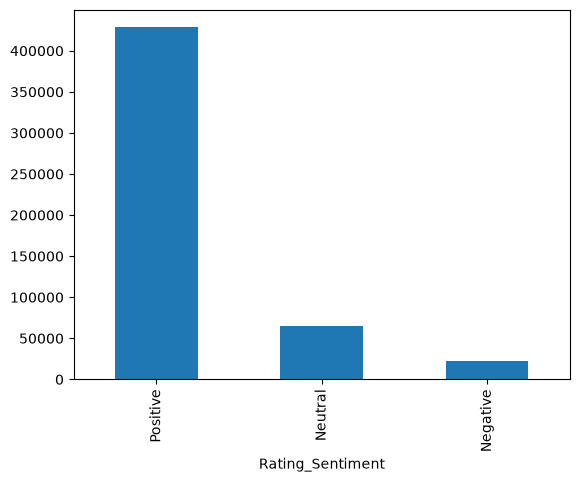

In [18]:
df["Rating_Sentiment"].value_counts().plot(kind="bar")

In [19]:
df.groupby("Rating_Sentiment")["Processed_Review"].apply(lambda x: x.sample(3, random_state=42))

Rating_Sentiment        
Negative          469070             breakfast room lobby no sound insulation
                  378279    staff friendly superior room small bathroom sl...
                  155041    no positive window room looked ground floor lo...
Neutral           71110                              shower long connect wifi
                  354357                       near train station no negative
                  138398    location brand took 45mins make check whole gr...
Positive          139486          location great got charged twice hotel room
                  93283     staff pleasant helpful breakfast small dining ...
                  19489                          nice quiet clean no negative
Name: Processed_Review, dtype: str

In [20]:
!pip install vaderSentiment


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [22]:
analyzer = SentimentIntensityAnalyzer()

In [23]:
sample_reviews = df["Review_Text"].dropna().sample(5, random_state=42)

for review in sample_reviews:
    scores = analyzer.polarity_scores(review)
    
    print("Review:", review)
    print("Sentiment Scores:", scores)
    print("-" * 80)

Review: staff were ultra efficient and friendly they couldn t do enough for you breakfast was amazing rooms were a bit shabby and in need of updating shower head didn t work well wasn t impressed with being charged 55 for 4 cocktails either thought the car park costs were extortionate
Sentiment Scores: {'neg': 0.03, 'neu': 0.724, 'pos': 0.247, 'compound': 0.9217}
--------------------------------------------------------------------------------
Review: fast check in out lovely room very conveniently situated i keep coming back to the grange st pauls it s my choice when staying in central london for business or seeing friends it seems quiet and relaxed as it s not in a main business or tourist spot the hotel offers a just what i need for a short stay clean comfortable room excellent breakfast and 24 hour bar and food all within walking of the city and a short taxi ride from the west end no negative
Sentiment Scores: {'neg': 0.0, 'neu': 0.78, 'pos': 0.22, 'compound': 0.9712}
--------------

In [24]:
!pip install transformers torch


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
import transformers

print("Transformers version:", transformers.__version__)

Transformers version: 5.16.1


In [26]:
from transformers import pipeline

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [27]:
for review in sample_reviews:
    result = sentiment_pipeline(review)
    
    print("Review:", review)
    print("Transformer Result:", result)
    print("-" * 80)

Review: staff were ultra efficient and friendly they couldn t do enough for you breakfast was amazing rooms were a bit shabby and in need of updating shower head didn t work well wasn t impressed with being charged 55 for 4 cocktails either thought the car park costs were extortionate
Transformer Result: [{'label': 'NEGATIVE', 'score': 0.992558479309082}]
--------------------------------------------------------------------------------
Review: fast check in out lovely room very conveniently situated i keep coming back to the grange st pauls it s my choice when staying in central london for business or seeing friends it seems quiet and relaxed as it s not in a main business or tourist spot the hotel offers a just what i need for a short stay clean comfortable room excellent breakfast and 24 hour bar and food all within walking of the city and a short taxi ride from the west end no negative
Transformer Result: [{'label': 'POSITIVE', 'score': 0.9989451766014099}]
--------------------------

In [28]:
three_class_pipeline = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest"
)

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

d:\Python\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\krish\.cache\huggingface\hub\models--cardiffnlp--twitter-roberta-base-sentiment-latest. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

In [29]:
for review in sample_reviews:
    result = three_class_pipeline(review)
    
    print("Review:", review)
    print("3-Class Transformer Result:", result)
    print("-" * 80)

Review: staff were ultra efficient and friendly they couldn t do enough for you breakfast was amazing rooms were a bit shabby and in need of updating shower head didn t work well wasn t impressed with being charged 55 for 4 cocktails either thought the car park costs were extortionate
3-Class Transformer Result: [{'label': 'negative', 'score': 0.5066181421279907}]
--------------------------------------------------------------------------------
Review: fast check in out lovely room very conveniently situated i keep coming back to the grange st pauls it s my choice when staying in central london for business or seeing friends it seems quiet and relaxed as it s not in a main business or tourist spot the hotel offers a just what i need for a short stay clean comfortable room excellent breakfast and 24 hour bar and food all within walking of the city and a short taxi ride from the west end no negative
3-Class Transformer Result: [{'label': 'positive', 'score': 0.9515514969825745}]
---------

In [32]:
evaluation_sample = pd.concat([
    df[df["Rating_Sentiment"] == "Positive"].sample(500, random_state=42),
    df[df["Rating_Sentiment"] == "Neutral"].sample(500, random_state=42),
    df[df["Rating_Sentiment"] == "Negative"].sample(500, random_state=42)
]).sample(frac=1, random_state=42).reset_index(drop=True)

In [33]:
evaluation_sample["Rating_Sentiment"].value_counts()

Rating_Sentiment
Negative    500
Positive    500
Neutral     500
Name: count, dtype: int64

In [34]:
evaluation_sample["Review_Text"].isna().sum()

np.int64(0)

In [35]:
evaluation_texts = evaluation_sample["Review_Text"].tolist()

transformer_results = three_class_pipeline(
    evaluation_texts,
    batch_size=16,
    truncation=True,
    max_length=512
)

In [36]:
transformer_results[:5]

[{'label': 'neutral', 'score': 0.5671402215957642},
 {'label': 'negative', 'score': 0.8905224204063416},
 {'label': 'neutral', 'score': 0.6383893489837646},
 {'label': 'positive', 'score': 0.9798904657363892},
 {'label': 'positive', 'score': 0.9860045313835144}]

In [37]:
evaluation_sample["Predicted_Sentiment"] = [
    result["label"].capitalize()
    for result in transformer_results
]

evaluation_sample["Confidence_Score"] = [
    result["score"]
    for result in transformer_results
]

In [38]:
evaluation_sample[
    ["Review_Text", "Rating_Sentiment", "Predicted_Sentiment", "Confidence_Score"]
].head()

,Review_Text,Rating_Sentiment,Predicted_Sentiment,Confidence_Score
0,no positive having to pay to use the spa,Negative,Neutral,0.567140
1,no positive maintenance poor ie toilet door br...,Negative,Negative,0.890522
2,location cleanless no negative,Positive,Neutral,0.638389
3,fantastic location staff breakfast roof terrac...,Positive,Positive,0.979890
4,the location was perfect for gig at wembley ar...,Positive,Positive,0.986005


In [39]:
agreement = (
    evaluation_sample["Rating_Sentiment"]
    == evaluation_sample["Predicted_Sentiment"]
).mean()

print(f"Model Agreement: {agreement:.2%}")

Model Agreement: 56.73%


In [1]:
import sklearn
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.0


In [8]:
import pandas as pd

df = pd.read_csv("../data/cleaned/Hotel_Reviews_Cleaned.csv")

print(df.shape)
print(df.columns.tolist())

(515212, 17)
['Hotel_Address', 'Additional_Number_of_Scoring', 'Review_Date', 'Average_Score', 'Hotel_Name', 'Reviewer_Nationality', 'Negative_Review', 'Review_Total_Negative_Word_Counts', 'Total_Number_of_Reviews', 'Positive_Review', 'Review_Total_Positive_Word_Counts', 'Total_Number_of_Reviews_Reviewer_Has_Given', 'Reviewer_Score', 'Tags', 'days_since_review', 'lat', 'lng']


In [9]:
def rating_to_sentiment(score):
    if score >= 8:
        return "Positive"
    elif score >= 6:
        return "Neutral"
    else:
        return "Negative"

df["Rating_Sentiment"] = df["Reviewer_Score"].apply(rating_to_sentiment)

print(df["Rating_Sentiment"].value_counts())

Rating_Sentiment
Positive    335355
Neutral     127441
Negative     52416
Name: count, dtype: int64


In [10]:
df["Review_Text"] = (
    df["Positive_Review"].fillna("") + " " +
    df["Negative_Review"].fillna("")
)

print(df["Review_Text"].head())
print("Missing Review_Text:", df["Review_Text"].isna().sum())

0    Only the park outside of the hotel was beautif...
1    No real complaints the hotel was great great l...
2    Location was good and staff were ok It is cute...
3    Great location in nice surroundings the bar an...
4    Amazing location and building Romantic setting...
Name: Review_Text, dtype: str
Missing Review_Text: 0


In [11]:
evaluation_sample = pd.concat([
    df[df["Rating_Sentiment"] == "Positive"].sample(500, random_state=42),
    df[df["Rating_Sentiment"] == "Neutral"].sample(500, random_state=42),
    df[df["Rating_Sentiment"] == "Negative"].sample(500, random_state=42)
]).sample(frac=1, random_state=42).reset_index(drop=True)

print(evaluation_sample["Rating_Sentiment"].value_counts())
print("Missing Review_Text:", evaluation_sample["Review_Text"].isna().sum())

Rating_Sentiment
Negative    500
Positive    500
Neutral     500
Name: count, dtype: int64
Missing Review_Text: 0


In [12]:
import transformers
print("Transformers version:", transformers.__version__)

Transformers version: 5.16.1


In [ ]:
from transformers import pipeline

three_class_pipeline = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest"
)

print("Three-class pipeline loaded successfully!")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Three-class pipeline loaded successfully!


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

In [14]:
evaluation_texts = evaluation_sample["Review_Text"].tolist()

transformer_results = three_class_pipeline(
    evaluation_texts,
    batch_size=16,
    truncation=True,
    max_length=512
)

print("Predictions generated:", len(transformer_results))

d:\Python\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\krish\.cache\huggingface\hub\models--cardiffnlp--twitter-roberta-base-sentiment-latest. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Predictions generated: 1500


In [15]:
evaluation_sample["Predicted_Sentiment"] = [
    result["label"]
    for result in transformer_results
]

print(evaluation_sample["Predicted_Sentiment"].value_counts())

Predicted_Sentiment
positive    725
negative    515
neutral     260
Name: count, dtype: int64


In [16]:
evaluation_sample["Predicted_Sentiment"] = (
    evaluation_sample["Predicted_Sentiment"]
    .str.capitalize()
)

print(evaluation_sample["Predicted_Sentiment"].value_counts())

Predicted_Sentiment
Positive    725
Negative    515
Neutral     260
Name: count, dtype: int64


In [17]:
from sklearn.metrics import classification_report

print(
    classification_report(
        evaluation_sample["Rating_Sentiment"],
        evaluation_sample["Predicted_Sentiment"]
    )
)

              precision    recall  f1-score   support

    Negative       0.67      0.69      0.68       500
     Neutral       0.42      0.22      0.29       500
    Positive       0.55      0.80      0.66       500

    accuracy                           0.57      1500
   macro avg       0.55      0.57      0.54      1500
weighted avg       0.55      0.57      0.54      1500



In [18]:
agreement = (
    evaluation_sample["Rating_Sentiment"]
    == evaluation_sample["Predicted_Sentiment"]
).mean()

print(f"Model Agreement: {agreement:.2%}")

Model Agreement: 57.07%


In [19]:
evaluation_sample["Transformer_Score"] = [
    result["score"]
    for result in transformer_results
]

print(evaluation_sample[
    ["Review_Text", "Predicted_Sentiment", "Transformer_Score"]
].head())

print("\nAverage confidence:",
      round(evaluation_sample["Transformer_Score"].mean(), 3))

                                         Review_Text Predicted_Sentiment  \
0  Really were looking forward to staying at this...            Negative   
1  Location was great really close to Paddington ...            Positive   
2  The location is very convenient just 10 minute...            Positive   
3  location is fantastic rooms are nice and clean...            Positive   
4  Very friendly staff and very helpful Very nice...            Positive   

   Transformer_Score  
0           0.858546  
1           0.730640  
2           0.982238  
3           0.978315  
4           0.974578  

Average confidence: 0.784


In [21]:
import nltk

nltk.download("vader_lexicon")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...


True

In [22]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()

print("VADER loaded successfully!")

VADER loaded successfully!


In [23]:
test_texts = df["Review_Text"].head(1000).tolist()

test_scores = [
    vader.polarity_scores(text)["compound"]
    for text in test_texts
]

print("Scores generated:", len(test_scores))
print("First 10 scores:", test_scores[:10])

Scores generated: 1000
First 10 scores: [-0.9245, 0.834, -0.2263, 0.191, 0.5263, 0.9287, 0.8074, 0.9468, -0.2308, 0.8074]


In [24]:
import numpy as np
import time

texts = df["Review_Text"].fillna("").tolist()

vader_scores = []

chunk_size = 10000
start_time = time.time()

for start in range(0, len(texts), chunk_size):
    chunk = texts[start:start + chunk_size]

    chunk_scores = [
        vader.polarity_scores(text)["compound"]
        for text in chunk
    ]

    vader_scores.extend(chunk_scores)

    if (start // chunk_size + 1) % 5 == 0:
        print(f"Processed: {min(start + chunk_size, len(texts)):,} / {len(texts):,}")

print(f"\nCompleted: {len(vader_scores):,} scores")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

Processed: 50,000 / 515,212
Processed: 100,000 / 515,212
Processed: 150,000 / 515,212
Processed: 200,000 / 515,212
Processed: 250,000 / 515,212
Processed: 300,000 / 515,212
Processed: 350,000 / 515,212
Processed: 400,000 / 515,212
Processed: 450,000 / 515,212
Processed: 500,000 / 515,212

Completed: 515,212 scores
Time taken: 2.38 minutes


In [25]:
df["VADER_Compound"] = vader_scores

print(df[["Review_Text", "VADER_Compound"]].head())
print("\nScores:", len(df["VADER_Compound"]))
print("Missing scores:", df["VADER_Compound"].isna().sum())

                                         Review_Text  VADER_Compound
0  Only the park outside of the hotel was beautif...         -0.9245
1  No real complaints the hotel was great great l...          0.8340
2  Location was good and staff were ok It is cute...         -0.2263
3  Great location in nice surroundings the bar an...          0.1910
4  Amazing location and building Romantic setting...          0.5263

Scores: 515212
Missing scores: 0


In [26]:
def vader_to_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"


df["VADER_Sentiment"] = df["VADER_Compound"].apply(vader_to_sentiment)

print(df["VADER_Sentiment"].value_counts())
print("\nPercentages:")
print(
    (df["VADER_Sentiment"].value_counts(normalize=True) * 100)
    .round(2)
)

VADER_Sentiment
Positive    369929
Negative    108653
Neutral      36630
Name: count, dtype: int64

Percentages:
VADER_Sentiment
Positive    71.80
Negative    21.09
Neutral      7.11
Name: proportion, dtype: float64


In [27]:
output_path = "../data/cleaned/Hotel_Reviews_Sentiment.csv"

df.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Saved to:", output_path)

Dataset saved successfully!
Rows: 515212
Columns: 21
Saved to: ../data/cleaned/Hotel_Reviews_Sentiment.csv


In [28]:
sentiment_summary = (
    df["VADER_Sentiment"]
    .value_counts()
    .rename_axis("Sentiment")
    .reset_index(name="Review_Count")
)

sentiment_summary["Percentage"] = (
    sentiment_summary["Review_Count"]
    / sentiment_summary["Review_Count"].sum()
    * 100
).round(2)

print(sentiment_summary)

  Sentiment  Review_Count  Percentage
0  Positive        369929       71.80
1  Negative        108653       21.09
2   Neutral         36630        7.11


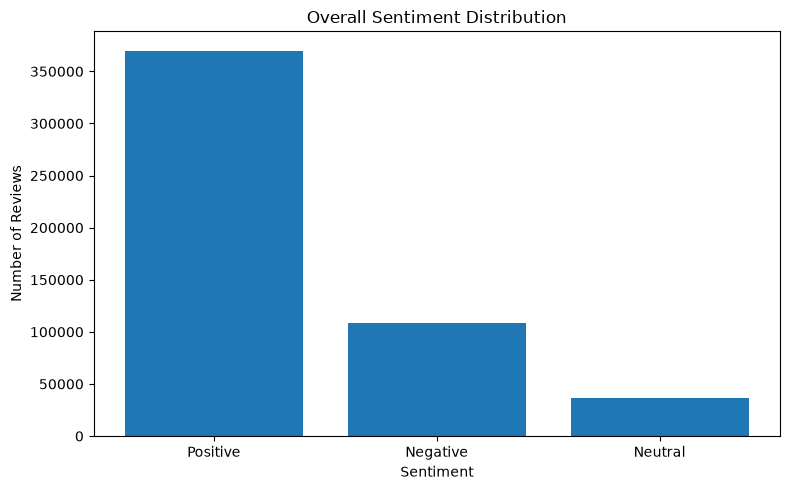

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    sentiment_summary["Sentiment"],
    sentiment_summary["Review_Count"]
)

plt.title("Overall Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [30]:
hotel_sentiment = (
    df.groupby("Hotel_Name")["VADER_Sentiment"]
    .value_counts()
    .unstack(fill_value=0)
    .reset_index()
)

hotel_sentiment.head()

VADER_Sentiment,Hotel_Name,Negative,Neutral,Positive
0,11 Cadogan Gardens,37,11,111
1,1K Hotel,34,10,104
2,25hours Hotel beim MuseumsQuartier,121,41,527
3,41,23,5,75
4,45 Park Lane Dorchester Collection,7,6,15


In [31]:
hotel_sentiment["Total_Reviews"] = (
    hotel_sentiment["Negative"]
    + hotel_sentiment["Neutral"]
    + hotel_sentiment["Positive"]
)

hotel_sentiment["Positive_%"] = (
    hotel_sentiment["Positive"]
    / hotel_sentiment["Total_Reviews"]
    * 100
).round(2)

hotel_sentiment["Negative_%"] = (
    hotel_sentiment["Negative"]
    / hotel_sentiment["Total_Reviews"]
    * 100
).round(2)

hotel_sentiment["Neutral_%"] = (
    hotel_sentiment["Neutral"]
    / hotel_sentiment["Total_Reviews"]
    * 100
).round(2)

hotel_sentiment.head()

VADER_Sentiment,Hotel_Name,Negative,Neutral,Positive,Total_Reviews,Positive_%,Negative_%,Neutral_%
0,11 Cadogan Gardens,37,11,111,159,69.81,23.27,6.92
1,1K Hotel,34,10,104,148,70.27,22.97,6.76
2,25hours Hotel beim MuseumsQuartier,121,41,527,689,76.49,17.56,5.95
3,41,23,5,75,103,72.82,22.33,4.85
4,45 Park Lane Dorchester Collection,7,6,15,28,53.57,25.00,21.43


In [32]:
top_positive_hotels = (
    hotel_sentiment[
        hotel_sentiment["Total_Reviews"] >= 100
    ]
    .sort_values("Positive_%", ascending=False)
    .head(10)
)

top_positive_hotels[
    ["Hotel_Name", "Total_Reviews", "Positive_%", "Negative_%", "Neutral_%"]
]

VADER_Sentiment,Hotel_Name,Total_Reviews,Positive_%,Negative_%,Neutral_%
209,Catalonia Magdalenes,311,91.00,6.75,2.25
411,H tel Da Vinci Spa,146,89.04,8.90,2.05
754,Hotel Sans Souci Wien,235,88.51,8.51,2.98
454,H tel R de Paris Boutique Hotel,113,87.61,8.85,3.54
624,Hotel Domizil,225,87.11,10.22,2.67
765,Hotel Spadari Al Duomo,243,86.42,9.05,4.53
1201,Residence Henri IV,171,85.96,10.53,3.51
598,Hotel Casa Camper,301,85.71,10.63,3.65
432,H tel L Echiquier Op ra Paris MGallery by Sofitel,139,85.61,11.51,2.88
771,Hotel The Serras,213,85.45,11.74,2.82


In [33]:
top_negative_hotels = (
    hotel_sentiment[
        hotel_sentiment["Total_Reviews"] >= 100
    ]
    .sort_values("Negative_%", ascending=False)
    .head(10)
)

top_negative_hotels[
    ["Hotel_Name", "Total_Reviews", "Negative_%", "Positive_%", "Neutral_%"]
]

VADER_Sentiment,Hotel_Name,Total_Reviews,Negative_%,Positive_%,Neutral_%
1412,The Westin Paris Vend me,111,41.44,48.65,9.91
1100,Novotel Suites Paris Nord 18 me,180,40.00,51.11,8.89
237,Commodore Hotel,953,36.62,56.24,7.14
1401,The Tophams Hotel,180,36.11,57.78,6.11
542,Holiday Inn Paris Gare Montparnasse,331,35.95,53.78,10.27
1024,Mokinba Hotels King,152,34.87,50.66,14.47
822,Idea Hotel Milano San Siro,467,34.69,59.53,5.78
40,Amarante Beau Manoir,159,34.59,56.60,8.81
185,Britannia International Hotel Canary Wharf,4789,34.47,56.82,8.71
1233,Savoy Hotel Amsterdam,243,34.16,57.20,8.64


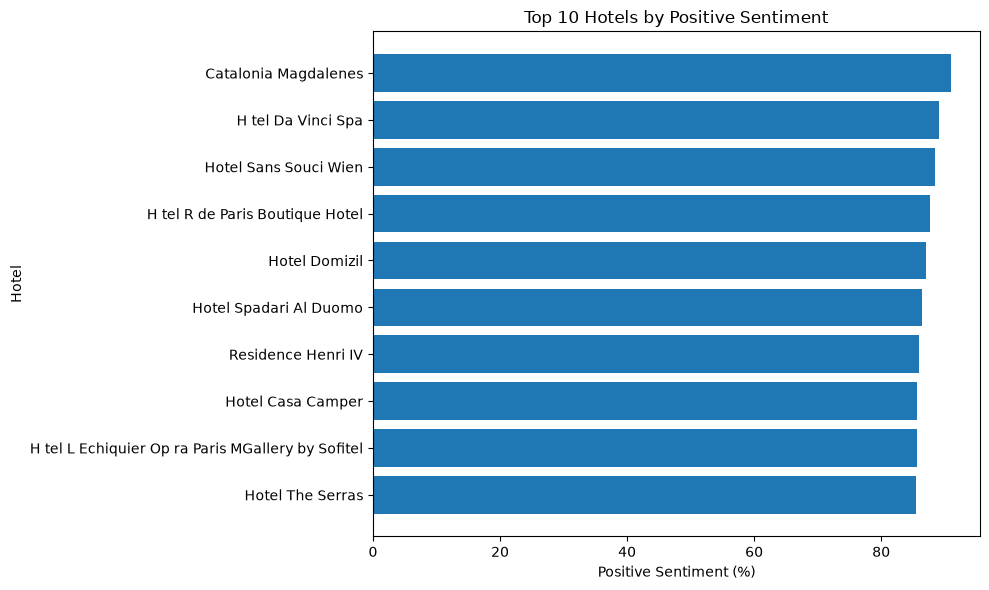

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_positive_hotels["Hotel_Name"],
    top_positive_hotels["Positive_%"]
)

plt.title("Top 10 Hotels by Positive Sentiment")
plt.xlabel("Positive Sentiment (%)")
plt.ylabel("Hotel")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

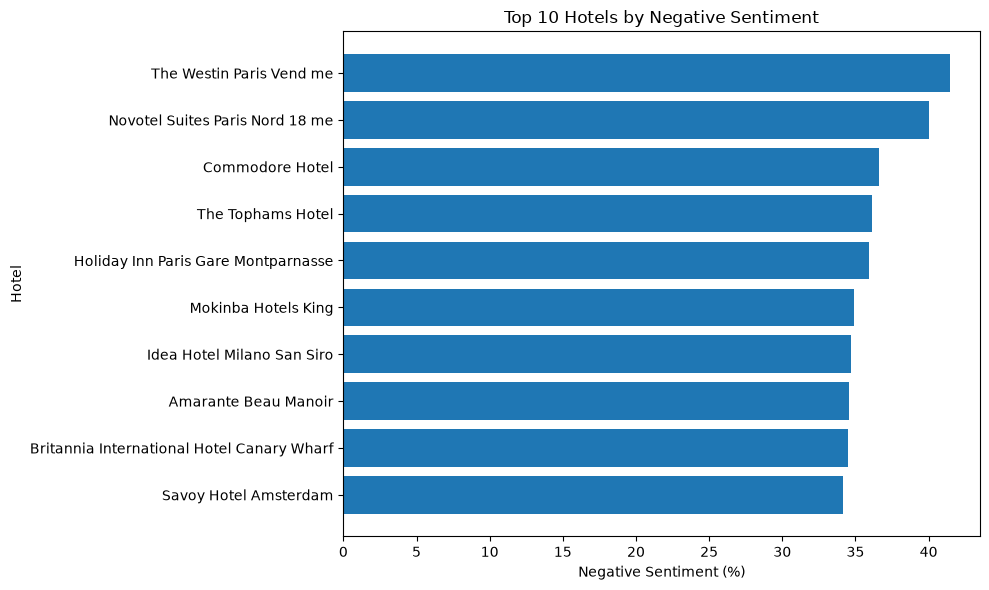

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_negative_hotels["Hotel_Name"],
    top_negative_hotels["Negative_%"]
)

plt.title("Top 10 Hotels by Negative Sentiment")
plt.xlabel("Negative Sentiment (%)")
plt.ylabel("Hotel")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [37]:
print(df["Hotel_Address"].head(10).to_list())

['s Gravesandestraat 55 Oost 1092 AA Amsterdam Netherlands', 's Gravesandestraat 55 Oost 1092 AA Amsterdam Netherlands', 's Gravesandestraat 55 Oost 1092 AA Amsterdam Netherlands', 's Gravesandestraat 55 Oost 1092 AA Amsterdam Netherlands', 's Gravesandestraat 55 Oost 1092 AA Amsterdam Netherlands', 's Gravesandestraat 55 Oost 1092 AA Amsterdam Netherlands', 's Gravesandestraat 55 Oost 1092 AA Amsterdam Netherlands', 's Gravesandestraat 55 Oost 1092 AA Amsterdam Netherlands', 's Gravesandestraat 55 Oost 1092 AA Amsterdam Netherlands', 's Gravesandestraat 55 Oost 1092 AA Amsterdam Netherlands']


In [38]:
def extract_city(address):
    address = str(address)

    if "Amsterdam" in address:
        return "Amsterdam"
    elif "Barcelona" in address:
        return "Barcelona"
    elif "London" in address:
        return "London"
    elif "Milan" in address:
        return "Milan"
    elif "Paris" in address:
        return "Paris"
    elif "Vienna" in address:
        return "Vienna"
    else:
        return "Unknown"


df["City"] = df["Hotel_Address"].apply(extract_city)

print(df["City"].value_counts())

City
London       262298
Barcelona     60149
Paris         59191
Amsterdam     57433
Vienna        38937
Milan         37204
Name: count, dtype: int64


In [39]:
city_sentiment = (
    df.groupby("City")["VADER_Sentiment"]
    .value_counts()
    .unstack(fill_value=0)
    .reset_index()
)

city_sentiment["Total_Reviews"] = (
    city_sentiment["Positive"]
    + city_sentiment["Negative"]
    + city_sentiment["Neutral"]
)

# Convert sentiment counts into percentages
for sentiment in ["Positive", "Negative", "Neutral"]:
    city_sentiment[f"{sentiment}_%"] = (
        city_sentiment[sentiment]
        / city_sentiment["Total_Reviews"]
        * 100
    ).round(2)

city_sentiment

VADER_Sentiment,City,Negative,Neutral,Positive,Total_Reviews,Positive_%,Negative_%,Neutral_%
0,Amsterdam,11287,3747,42399,57433,73.82,19.65,6.52
1,Barcelona,12005,3854,44290,60149,73.63,19.96,6.41
2,London,56225,19372,186701,262298,71.18,21.44,7.39
3,Milan,8435,2803,25966,37204,69.79,22.67,7.53
4,Paris,12521,4354,42316,59191,71.49,21.15,7.36
5,Vienna,8180,2500,28257,38937,72.57,21.01,6.42


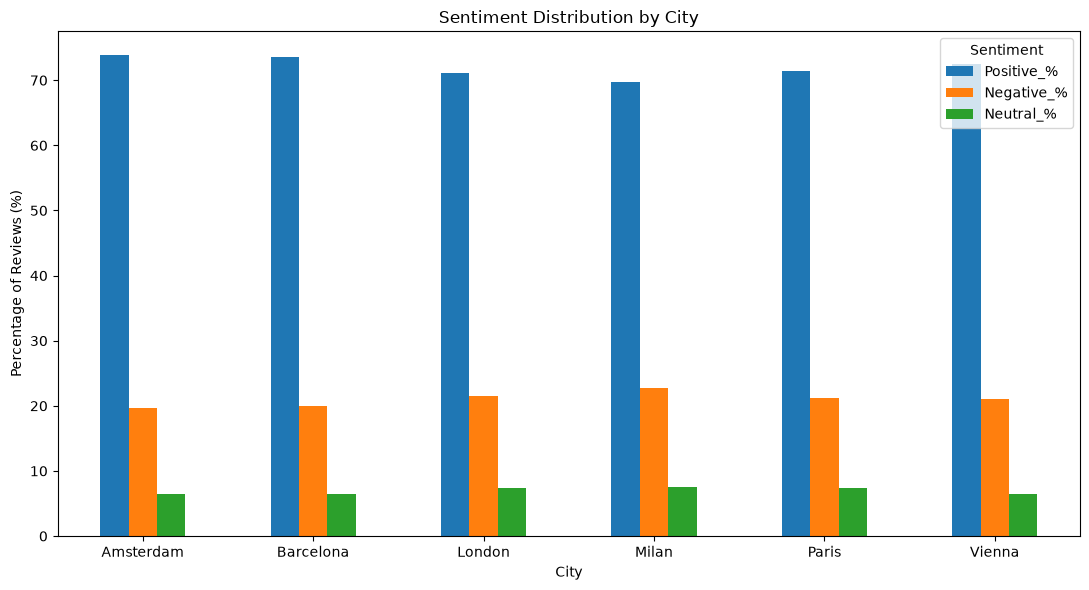

In [40]:
import matplotlib.pyplot as plt

city_plot = city_sentiment.set_index("City")[
    ["Positive_%", "Negative_%", "Neutral_%"]
]

city_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Sentiment Distribution by City")
plt.xlabel("City")
plt.ylabel("Percentage of Reviews (%)")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [41]:
print("Earliest review:", df["Review_Date"].min())
print("Latest review:", df["Review_Date"].max())

Earliest review: 2015-08-04
Latest review: 2017-08-03


In [43]:
df["Review_Date"] = pd.to_datetime(df["Review_Date"], errors="coerce")

print(df["Review_Date"].dtype)
print("Missing dates:", df["Review_Date"].isna().sum())

datetime64[us]
Missing dates: 0


In [44]:
df["Review_Month"] = df["Review_Date"].dt.to_period("M").astype(str)

monthly_sentiment = (
    df.groupby("Review_Month")["VADER_Sentiment"]
    .value_counts()
    .unstack(fill_value=0)
    .reset_index()
)

monthly_sentiment["Total_Reviews"] = (
    monthly_sentiment["Positive"]
    + monthly_sentiment["Negative"]
    + monthly_sentiment["Neutral"]
)

for sentiment in ["Positive", "Negative", "Neutral"]:
    monthly_sentiment[f"{sentiment}_%"] = (
        monthly_sentiment[sentiment]
        / monthly_sentiment["Total_Reviews"]
        * 100
    ).round(2)

monthly_sentiment.head()

VADER_Sentiment,Review_Month,Negative,Neutral,Positive,Total_Reviews,Positive_%,Negative_%,Neutral_%
0,2015-08,4707,1438,13142,19287,68.14,24.41,7.46
1,2015-09,4885,1661,13143,19689,66.75,24.81,8.44
2,2015-10,4852,1588,13009,19449,66.89,24.95,8.16
3,2015-11,4291,1403,12345,18039,68.44,23.79,7.78
4,2015-12,4139,1340,12435,17914,69.41,23.10,7.48


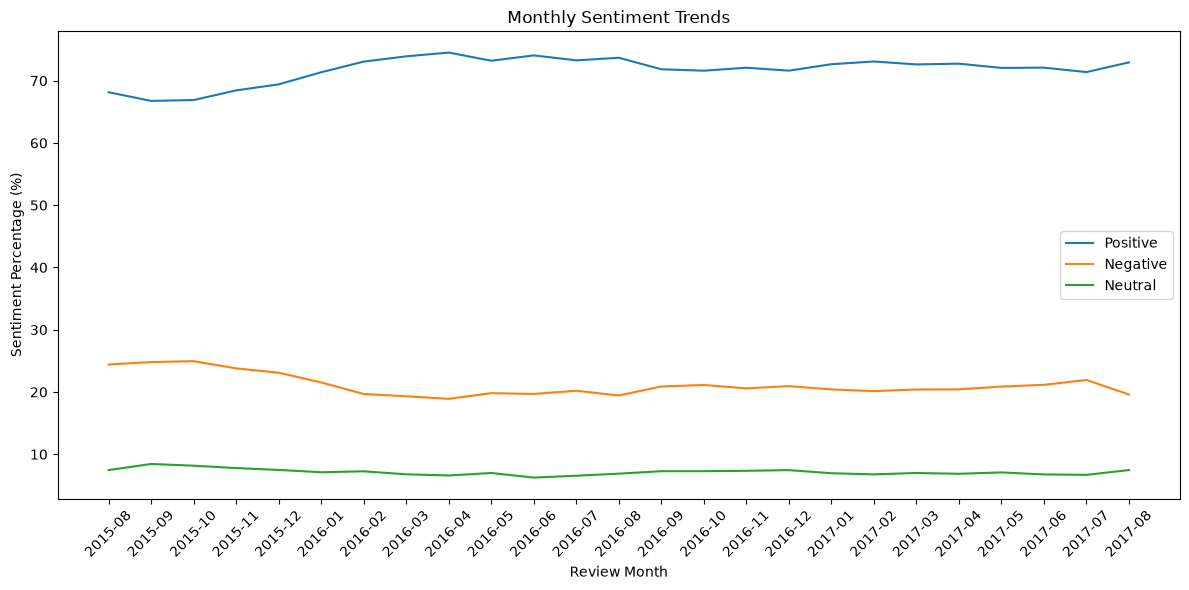

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sentiment["Review_Month"],
    monthly_sentiment["Positive_%"],
    label="Positive"
)

plt.plot(
    monthly_sentiment["Review_Month"],
    monthly_sentiment["Negative_%"],
    label="Negative"
)

plt.plot(
    monthly_sentiment["Review_Month"],
    monthly_sentiment["Neutral_%"],
    label="Neutral"
)

plt.title("Monthly Sentiment Trends")
plt.xlabel("Review Month")
plt.ylabel("Sentiment Percentage (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [46]:
top_positive_months = (
    monthly_sentiment
    .sort_values("Positive_%", ascending=False)
    .head(5)
)

top_negative_months = (
    monthly_sentiment
    .sort_values("Negative_%", ascending=False)
    .head(5)
)

print("Top 5 Months by Positive Sentiment:")
display(
    top_positive_months[
        ["Review_Month", "Total_Reviews", "Positive_%", "Negative_%", "Neutral_%"]
    ]
)

print("\nTop 5 Months by Negative Sentiment:")
display(
    top_negative_months[
        ["Review_Month", "Total_Reviews", "Positive_%", "Negative_%", "Neutral_%"]
    ]
)

Top 5 Months by Positive Sentiment:


VADER_Sentiment,Review_Month,Total_Reviews,Positive_%,Negative_%,Neutral_%
8,2016-04,21471,74.51,18.90,6.59
10,2016-06,20920,74.06,19.69,6.25
7,2016-03,20722,73.91,19.31,6.78
12,2016-08,27252,73.68,19.44,6.88
11,2016-07,25865,73.26,20.20,6.55



Top 5 Months by Negative Sentiment:


VADER_Sentiment,Review_Month,Total_Reviews,Positive_%,Negative_%,Neutral_%
2,2015-10,19449,66.89,24.95,8.16
1,2015-09,19689,66.75,24.81,8.44
0,2015-08,19287,68.14,24.41,7.46
3,2015-11,18039,68.44,23.79,7.78
4,2015-12,17914,69.41,23.10,7.48


In [47]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"


df["Season"] = df["Review_Date"].dt.month.apply(get_season)

season_sentiment = (
    df.groupby("Season")["VADER_Sentiment"]
    .value_counts()
    .unstack(fill_value=0)
    .reset_index()
)

season_sentiment["Total_Reviews"] = (
    season_sentiment["Positive"]
    + season_sentiment["Negative"]
    + season_sentiment["Neutral"]
)

for sentiment in ["Positive", "Negative", "Neutral"]:
    season_sentiment[f"{sentiment}_%"] = (
        season_sentiment[sentiment]
        / season_sentiment["Total_Reviews"]
        * 100
    ).round(2)

season_sentiment

VADER_Sentiment,Season,Negative,Neutral,Positive,Total_Reviews,Positive_%,Negative_%,Neutral_%
0,Autumn,27580,9386,85087,122053,69.71,22.60,7.69
1,Spring,26029,8977,95383,130389,73.15,19.96,6.88
2,Summer,29919,9665,103154,142738,72.27,20.96,6.77
3,Winter,25125,8602,86305,120032,71.90,20.93,7.17


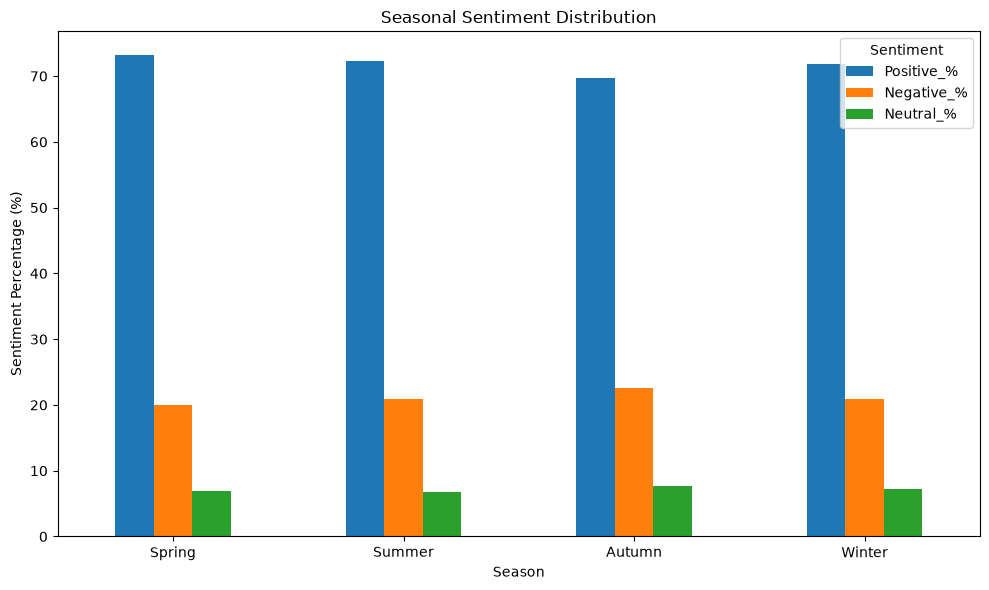

In [48]:
import matplotlib.pyplot as plt

season_order = ["Spring", "Summer", "Autumn", "Winter"]

season_plot = (
    season_sentiment
    .set_index("Season")
    .loc[season_order, ["Positive_%", "Negative_%", "Neutral_%"]]
)

season_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Seasonal Sentiment Distribution")
plt.xlabel("Season")
plt.ylabel("Sentiment Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [49]:
from collections import Counter

positive_text = " ".join(
    df.loc[df["VADER_Sentiment"] == "Positive", "Review_Text"]
    .fillna("")
)

positive_words = positive_text.lower().split()

positive_word_counts = Counter(positive_words)

positive_word_counts.most_common(20)

[('the', 828092),
 ('and', 524989),
 ('was', 378224),
 ('to', 324865),
 ('a', 324750),
 ('room', 244140),
 ('very', 225572),
 ('in', 219921),
 ('staff', 194901),
 ('of', 178701),
 ('for', 165078),
 ('hotel', 160693),
 ('location', 152974),
 ('is', 149667),
 ('no', 147831),
 ('i', 139016),
 ('we', 133773),
 ('it', 130214),
 ('were', 125994),
 ('good', 115975)]

In [50]:
import re
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

positive_words_clean = [
    word for word in positive_words
    if word not in stop_words and word.isalpha()
]

positive_word_counts_clean = Counter(positive_words_clean)

positive_word_counts_clean.most_common(20)

[('room', 244140),
 ('staff', 194901),
 ('hotel', 160693),
 ('location', 152974),
 ('good', 115975),
 ('breakfast', 115228),
 ('great', 107550),
 ('friendly', 83192),
 ('negative', 75975),
 ('helpful', 74343),
 ('nice', 71019),
 ('clean', 67523),
 ('bed', 62075),
 ('comfortable', 60567),
 ('rooms', 59979),
 ('excellent', 59363),
 ('small', 47366),
 ('would', 43397),
 ('stay', 41652),
 ('really', 37895)]

In [51]:
positive_review_text = " ".join(
    df.loc[
        df["VADER_Sentiment"] == "Positive",
        "Positive_Review"
    ].fillna("")
)

positive_review_words = positive_review_text.lower().split()

positive_review_words_clean = [
    word for word in positive_review_words
    if word not in stop_words and word.isalpha()
]

positive_review_counts = Counter(positive_review_words_clean)

positive_review_counts.most_common(20)

[('staff', 169573),
 ('location', 144607),
 ('room', 118981),
 ('hotel', 107988),
 ('good', 98783),
 ('great', 98761),
 ('friendly', 79770),
 ('breakfast', 71599),
 ('helpful', 71021),
 ('nice', 62302),
 ('clean', 61305),
 ('excellent', 57135),
 ('comfortable', 56146),
 ('bed', 41527),
 ('rooms', 35045),
 ('lovely', 33447),
 ('stay', 29012),
 ('really', 25375),
 ('positive', 24266),
 ('close', 24091)]

In [52]:
negative_review_text = " ".join(
    df.loc[
        df["VADER_Sentiment"] == "Negative",
        "Negative_Review"
    ].fillna("")
)

negative_review_words = negative_review_text.lower().split()

negative_review_words_clean = [
    word for word in negative_review_words
    if word not in stop_words and word.isalpha()
]

negative_review_counts = Counter(negative_review_words_clean)

negative_review_counts.most_common(20)

[('negative', 50798),
 ('room', 40786),
 ('hotel', 19100),
 ('staff', 12232),
 ('breakfast', 11448),
 ('poor', 8878),
 ('small', 7909),
 ('bed', 7618),
 ('rooms', 7574),
 ('one', 7073),
 ('night', 6136),
 ('bathroom', 5989),
 ('us', 5726),
 ('service', 5605),
 ('bad', 5481),
 ('reception', 5085),
 ('shower', 5071),
 ('would', 4974),
 ('could', 4475),
 ('even', 4424)]

In [53]:
negative_extra_words = {
    "negative",
    "one",
    "us",
    "would",
    "could",
    "even"
}

negative_review_words_final = [
    word for word in negative_review_words_clean
    if word not in negative_extra_words
]

negative_review_counts_final = Counter(negative_review_words_final)

negative_review_counts_final.most_common(20)

[('room', 40786),
 ('hotel', 19100),
 ('staff', 12232),
 ('breakfast', 11448),
 ('poor', 8878),
 ('small', 7909),
 ('bed', 7618),
 ('rooms', 7574),
 ('night', 6136),
 ('bathroom', 5989),
 ('service', 5605),
 ('bad', 5481),
 ('reception', 5085),
 ('shower', 5071),
 ('stay', 4255),
 ('get', 4199),
 ('also', 4098),
 ('check', 4074),
 ('time', 4035),
 ('noisy', 4002)]

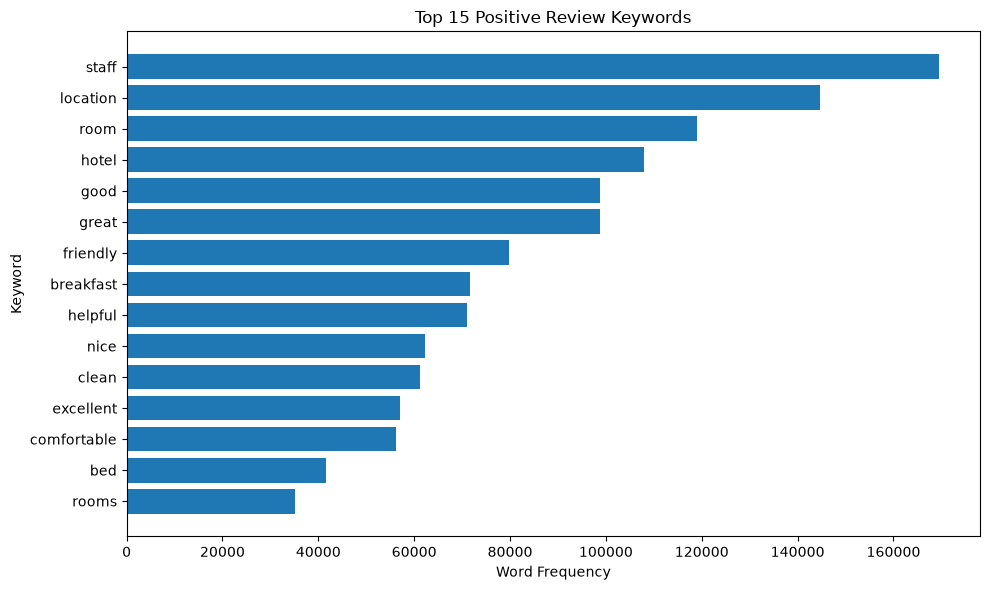

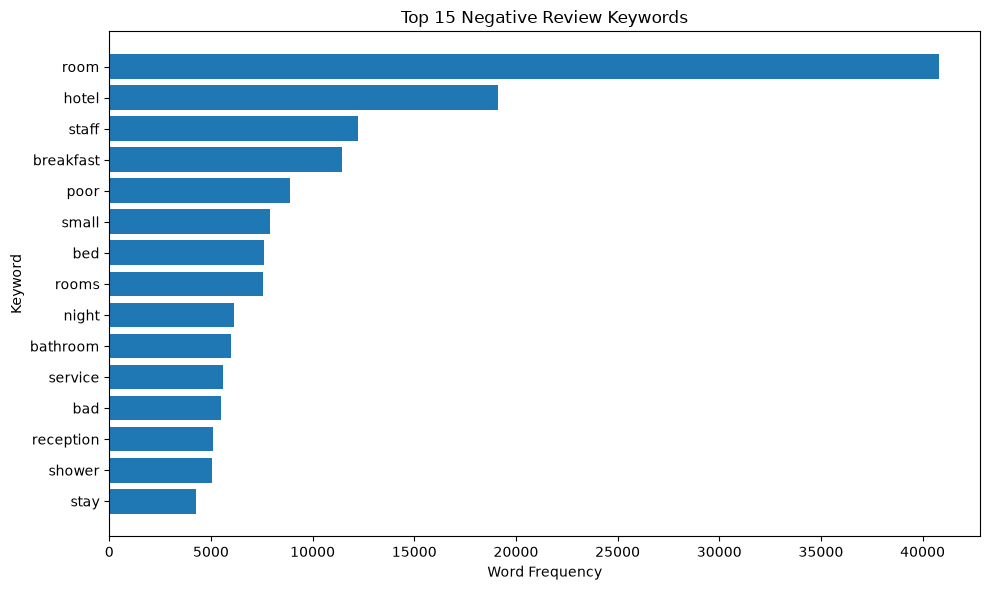

In [54]:
import matplotlib.pyplot as plt

# Top 15 positive keywords
top_positive_words = positive_review_counts.most_common(15)

plt.figure(figsize=(10, 6))

plt.barh(
    [word for word, count in top_positive_words[::-1]],
    [count for word, count in top_positive_words[::-1]]
)

plt.title("Top 15 Positive Review Keywords")
plt.xlabel("Word Frequency")
plt.ylabel("Keyword")
plt.tight_layout()
plt.show()


# Top 15 negative keywords
top_negative_words = negative_review_counts_final.most_common(15)

plt.figure(figsize=(10, 6))

plt.barh(
    [word for word, count in top_negative_words[::-1]],
    [count for word, count in top_negative_words[::-1]]
)

plt.title("Top 15 Negative Review Keywords")
plt.xlabel("Word Frequency")
plt.ylabel("Keyword")
plt.tight_layout()
plt.show()

In [55]:
df["Review_Word_Count"] = (
    df["Review_Text"]
    .fillna("")
    .str.split()
    .str.len()
)

review_length_by_sentiment = (
    df.groupby("VADER_Sentiment")["Review_Word_Count"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .reset_index()
)

review_length_by_sentiment

,VADER_Sentiment,count,mean,median,min,max
0,Negative,108653,29.00,15.0,2,689
1,Neutral,36630,15.34,9.0,0,390
2,Positive,369929,37.76,26.0,1,733


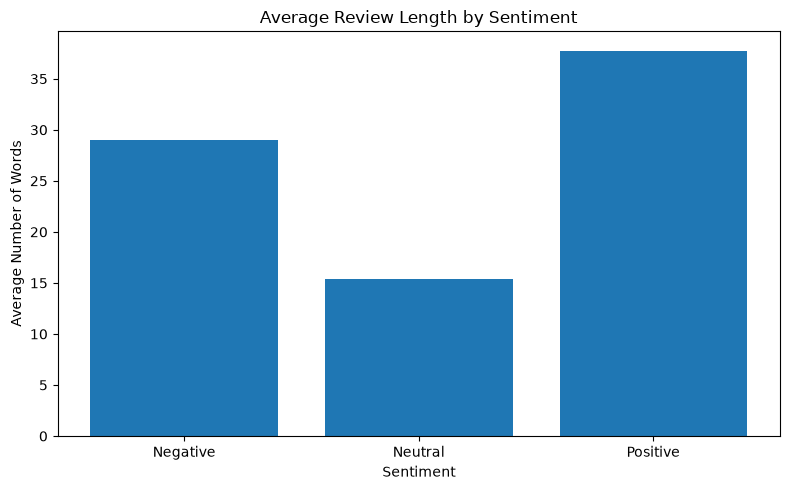

In [56]:
plt.figure(figsize=(8, 5))

plt.bar(
    review_length_by_sentiment["VADER_Sentiment"],
    review_length_by_sentiment["mean"]
)

plt.title("Average Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Number of Words")
plt.tight_layout()
plt.show()

In [57]:
nationality_counts = (
    df["Reviewer_Nationality"]
    .value_counts()
    .reset_index()
)

nationality_counts.columns = [
    "Reviewer_Nationality",
    "Review_Count"
]

nationality_counts.head(20)

,Reviewer_Nationality,Review_Count
0,United Kingdom,245110
1,United States of America,35349
2,Australia,21648
3,Ireland,14814
4,United Arab Emirates,10229
5,Saudi Arabia,8940
6,Netherlands,8757
7,Switzerland,8669
8,Germany,7929
9,Canada,7883


In [58]:
reliable_nationalities = nationality_counts[
    nationality_counts["Review_Count"] >= 1000
].copy()

print("Number of nationalities with at least 1,000 reviews:",
      len(reliable_nationalities))

reliable_nationalities

Number of nationalities with at least 1,000 reviews: 55


,Reviewer_Nationality,Review_Count
0,United Kingdom,245110
1,United States of America,35349
2,Australia,21648
3,Ireland,14814
4,United Arab Emirates,10229
5,Saudi Arabia,8940
6,Netherlands,8757
7,Switzerland,8669
8,Germany,7929
9,Canada,7883


In [59]:
nationality_sentiment = (
    df[df["Reviewer_Nationality"].isin(
        reliable_nationalities["Reviewer_Nationality"]
    )]
    .groupby("Reviewer_Nationality")["VADER_Sentiment"]
    .value_counts()
    .unstack(fill_value=0)
    .reset_index()
)

nationality_sentiment["Total_Reviews"] = (
    nationality_sentiment["Positive"]
    + nationality_sentiment["Negative"]
    + nationality_sentiment["Neutral"]
)

for sentiment in ["Positive", "Negative", "Neutral"]:
    nationality_sentiment[f"{sentiment}_%"] = (
        nationality_sentiment[sentiment]
        / nationality_sentiment["Total_Reviews"]
        * 100
    ).round(2)

nationality_sentiment.sort_values(
    "Positive_%",
    ascending=False
).head(10)

VADER_Sentiment,Reviewer_Nationality,Negative,Neutral,Positive,Total_Reviews,Positive_%,Negative_%,Neutral_%
32,New Zealand,591,168,2474,3233,76.52,18.28,5.20
13,Finland,345,88,1395,1828,76.31,18.87,4.81
54,United States of America,6542,1894,26913,35349,76.14,18.51,5.36
0,Australia,4009,1188,16451,21648,75.99,18.52,5.49
22,Ireland,2782,844,11188,14814,75.52,18.78,5.70
6,Canada,1512,446,5925,7883,75.16,19.18,5.66
53,United Kingdom,48413,15647,181050,245110,73.86,19.75,6.38
23,Israel,1319,415,4867,6601,73.73,19.98,6.29
18,Hungary,456,118,1610,2184,73.72,20.88,5.40
15,Germany,1720,439,5770,7929,72.77,21.69,5.54


In [60]:
top_negative_nationalities = (
    nationality_sentiment
    .sort_values("Negative_%", ascending=False)
    .head(10)
)

top_negative_nationalities

VADER_Sentiment,Reviewer_Nationality,Negative,Neutral,Positive,Total_Reviews,Positive_%,Negative_%,Neutral_%
21,Iran,317,140,626,1083,57.80,29.27,12.93
49,Thailand,524,196,1160,1880,61.70,27.87,10.43
41,Saudi Arabia,2443,1485,5012,8940,56.06,27.33,16.61
38,Qatar,739,440,1574,2753,57.17,26.84,15.98
24,Italy,1622,598,3893,6113,63.68,26.53,9.78
7,China,895,267,2231,3393,65.75,26.38,7.87
27,Lebanon,587,262,1398,2247,62.22,26.12,11.66
52,United Arab Emirates,2672,1192,6365,10229,62.23,26.12,11.65
37,Portugal,478,172,1187,1837,64.62,26.02,9.36
20,Indonesia,400,206,941,1547,60.83,25.86,13.32


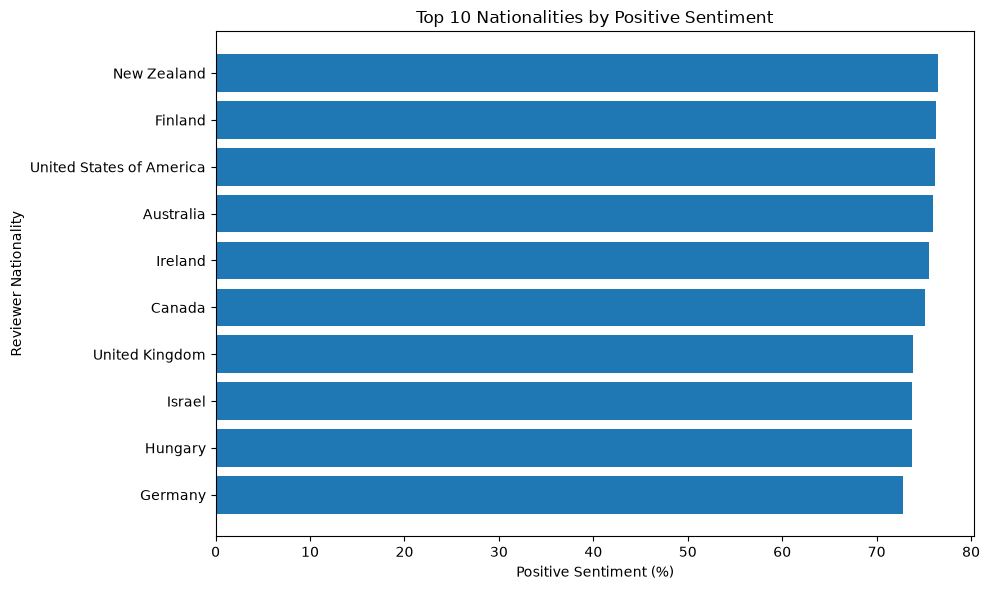

In [61]:
top_positive_nationalities = (
    nationality_sentiment
    .sort_values("Positive_%", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_positive_nationalities["Reviewer_Nationality"][::-1],
    top_positive_nationalities["Positive_%"][::-1]
)

plt.title("Top 10 Nationalities by Positive Sentiment")
plt.xlabel("Positive Sentiment (%)")
plt.ylabel("Reviewer Nationality")
plt.tight_layout()
plt.show()

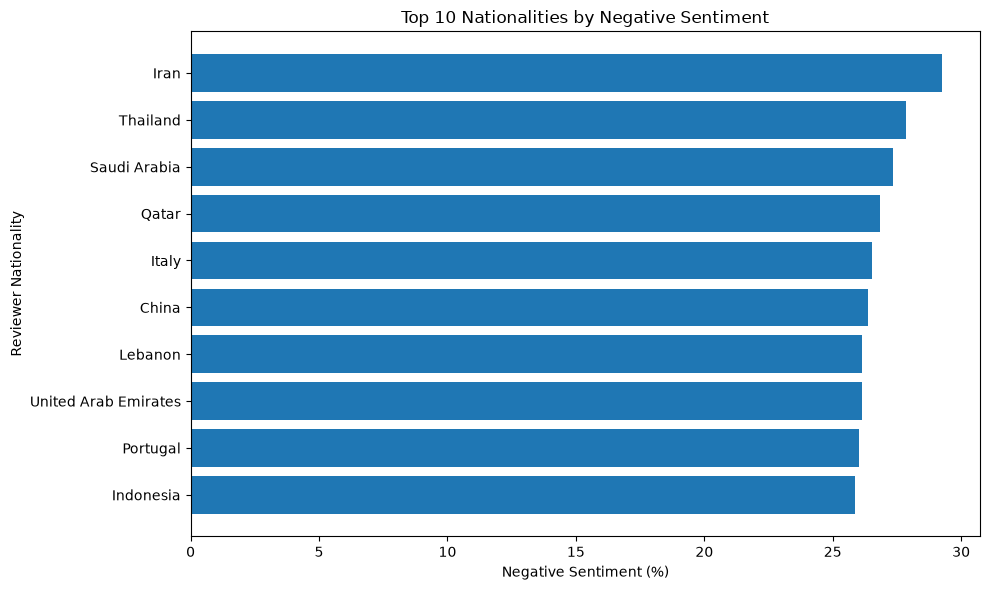

In [62]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_negative_nationalities["Reviewer_Nationality"][::-1],
    top_negative_nationalities["Negative_%"][::-1]
)

plt.title("Top 10 Nationalities by Negative Sentiment")
plt.xlabel("Negative Sentiment (%)")
plt.ylabel("Reviewer Nationality")
plt.tight_layout()
plt.show()

In [65]:
final_sentiment_summary = pd.DataFrame({
    "Metric": [
        "Overall Positive Sentiment",
        "Overall Negative Sentiment",
        "Overall Neutral Sentiment",
        "Most Positive City",
        "Most Negative City",
        "Most Positive Season",
        "Most Negative Season",
        "Most Positive Nationality",
        "Most Negative Nationality",
        "Average Positive Review Length",
        "Average Negative Review Length",
        "Average Neutral Review Length"
    ],
    "Result": [
        "71.80%",
        "21.09%",
        "7.11%",
        "Amsterdam (73.82%)",
        "Milan (22.67%)",
        "Spring (73.15%)",
        "Autumn (22.60%)",
        "New Zealand (76.52%)",
        "Iran (29.27%)",
        "37.76 words",
        "29.00 words",
        "15.34 words"
    ]
})

final_sentiment_summary

,Metric,Result
0,Overall Positive Sentiment,71.80%
1,Overall Negative Sentiment,21.09%
2,Overall Neutral Sentiment,7.11%
3,Most Positive City,Amsterdam (73.82%)
4,Most Negative City,Milan (22.67%)
5,Most Positive Season,Spring (73.15%)
6,Most Negative Season,Autumn (22.60%)
7,Most Positive Nationality,New Zealand (76.52%)
8,Most Negative Nationality,Iran (29.27%)
9,Average Positive Review Length,37.76 words


In [68]:
print("===== SENTIMENT ANALYSIS FINAL CHECK =====\n")

print("Dataset shape:", df.shape)

print("\nSentiment columns:")
print([
    "Rating_Sentiment",
    "VADER_Compound",
    "VADER_Sentiment"
])

print("\nMissing VADER scores:",
      df["VADER_Compound"].isna().sum())

print("Missing VADER labels:",
      df["VADER_Sentiment"].isna().sum())

print("\nVADER sentiment counts:")
print(df["VADER_Sentiment"].value_counts())

print("\nSentiment analysis verification complete.")

===== SENTIMENT ANALYSIS FINAL CHECK =====

Dataset shape: (515212, 25)

Sentiment columns:
['Rating_Sentiment', 'VADER_Compound', 'VADER_Sentiment']

Missing VADER scores: 0
Missing VADER labels: 0

VADER sentiment counts:
VADER_Sentiment
Positive    369929
Negative    108653
Neutral      36630
Name: count, dtype: int64

Sentiment analysis verification complete.
